In [5]:
import numpy as np

class PolynomialRegression:
    """
    Linear regression on features you choose:  y_hat = features(X) . w + b
 
    features: a function that turns raw X into feature columns
              (polynomial, log, sin, ... or a mix). None = plain linear regression.
    """
 
    def __init__(self, features=None, n_iter=10000, convergence_limit=1e-7, learning_rate=0.01):
        self.n_iter = n_iter
        self.convergence_limit = convergence_limit
        self.learning_rate = learning_rate
 
        if features is None:
            features = lambda X: X  # no transform = plain linear regression
        self.features = features
 
    def _make_features(self, X):
        X = np.asarray(X, dtype=float)
 
        if X.ndim == 1:
            X = X.reshape(-1, 1)
 
        return self.features(X)
 
    def _model(self, X):
        # One row (n,) -> one number. All rows (m, n) -> m predictions.
        y_hat = np.dot(X, self.weights) + self.bias
 
        return y_hat
 
    def _cost_function(self):
        f_wb = self._model(self.X)
 
        J_wb = f_wb - self.y
        J_wb = J_wb ** 2
        J_wb = np.sum(J_wb)
        J_wb = J_wb / (2 * self.m)
 
        return J_wb
 
    def _gradient(self):
        dL_dw = np.zeros(self.n)
        dL_db = 0
 
        for i in range(self.m):
            dL_df = self._model(self.X[i]) - self.y[i]
 
            dL_dw += dL_df * self.X[i]
            dL_db += dL_df
 
        dL_dw = dL_dw / self.m
        dL_db = dL_db / self.m
 
        return dL_dw, dL_db
 
    def _gradient_descent(self):
        for i in range(self.n_iter):
            dL_dw, dL_db = self._gradient()
 
            w_temp = self.weights - self.learning_rate * dL_dw
            b_temp = self.bias - self.learning_rate * dL_db
 
            self.weights = w_temp
            self.bias = b_temp
 
            self.history.append(self._cost_function())
 
            converged = len(self.history) > 1 and abs(self.history[-1] - self.history[-2]) < self.convergence_limit
            diverged = not np.isfinite(self.history[-1])
 
            if converged or diverged:
                break
 
        return self
 
    def fit(self, X, y):
        X = self._make_features(X)  # raw X -> feature columns (always BEFORE scaling)
        y = np.asarray(y, dtype=float).ravel()
 
        # Feature Scaling "z-score"
        self.mean = np.mean(X, axis=0)
 
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1.0
 
        self.X = (X - self.mean) / self.std
        self.y = y
 
        self.m = self.X.shape[0] # Number of Data Rows
        self.n = self.X.shape[1] # Number of Features
 
        self.weights = np.zeros(self.n)
        self.bias = 0
 
        self.history = []
 
        # Finding best parameters
        self._gradient_descent()
 
        return self
 
    def predict(self, X):
        X = self._make_features(X)  # same transform as in fit
        # Feature Rescaling (for test data), using mean/std from training
        X = (X - self.mean) / self.std
 
        y_hat = self._model(X)
 
        return y_hat
 
 
def poly(degree):
    # Feature function for a polynomial: x, x^2, ..., x^degree
    return lambda X: np.column_stack([X**p for p in range(1, degree + 1)])

In [6]:
# y = 2*x - 0.5*x^2 + 8*ln(x) + 3 + noise (noise std = 1), 100 samples
# x is between 0.1 and 10 (ln needs x > 0), with more samples near 0 where ln(x) changes fastest.
# X and y line up: the same row and column in both arrays is one sample.

X = np.array([
       4.12,    0.82,    0.12,    0.10,    6.65,
       8.35,    3.74,    5.37,    3.03,    8.76,
       6.69,    0.10,    7.38,    0.11,    5.37,
       0.41,    7.48,    3.00,    0.99,    1.87,
       0.11,    0.25,    4.55,    4.25,    3.85,
       1.56,    9.94,    9.62,    4.75,    4.29,
       4.79,    1.60,    0.28,    5.25,    2.83,
       1.05,    2.44,    7.93,    8.74,    1.37,
       3.33,    1.13,    3.60,    1.23,    1.62,
       7.95,    0.61,    3.94,    0.17,    6.96,
       6.23,    0.67,    7.71,    0.13,    1.22,
       0.32,    2.11,    6.38,    0.63,    0.13,
       1.72,    0.49,    0.18,    3.43,    0.98,
       4.57,    0.49,    8.89,    1.42,    0.21,
       4.02,    8.61,    2.02,    9.12,    2.57,
       1.89,    3.91,    9.90,    9.01,    2.20,
       5.78,    2.55,    2.87,    6.21,    1.80,
       5.44,    5.11,    8.70,    0.23,    5.36,
       8.62,    9.38,    0.10,    7.48,    9.63,
       9.17,    0.32,    9.47,    7.94,    6.80,
])

y = np.array([
      12.74,    1.31,  -13.23,  -14.24,    9.18,
       0.74,   14.91,   11.49,   12.62,    0.13,
       6.96,  -14.84,    5.94,  -14.33,   12.69,
      -3.19,    6.78,   12.53,    5.83,   10.73,
     -13.60,   -6.46,   14.66,   14.89,   14.15,
       7.03,   -8.28,   -6.69,   12.26,   14.29,
      13.07,    7.65,   -7.71,   13.25,   13.34,
       6.26,   12.03,    5.02,    1.03,    8.47,
      11.37,    6.83,   14.31,    6.78,    9.16,
       4.27,    0.40,   13.73,  -12.75,    8.11,
       9.88,    1.99,    4.75,  -12.99,    5.44,
      -6.04,   10.96,    8.75,    0.67,  -13.18,
       8.11,   -4.25,   -9.86,   13.54,    3.79,
      13.62,   -0.03,   -1.31,    7.72,  -10.57,
      15.74,    1.29,   11.69,   -2.62,   13.31,
      10.46,   14.70,   -8.02,   -3.46,   12.32,
       9.96,   12.10,   12.85,    9.70,   10.30,
      12.43,   12.78,    0.38,   -8.80,   14.18,
       0.67,   -4.80,  -17.17,    4.77,   -4.90,
      -3.03,   -5.81,   -3.27,    2.65,    8.23,
])

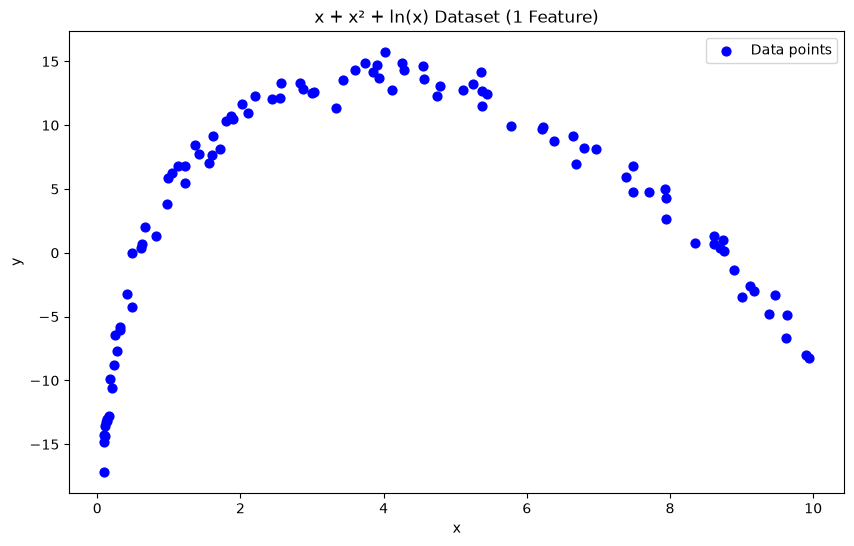

In [7]:
# Plot the data
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot data points
plt.scatter(X, y, color="blue", s=40, label="Data points")

# Labels
plt.xlabel("x")
plt.ylabel("y")
plt.title("x + x² + ln(x) Dataset (1 Feature)")

plt.legend()
plt.show()

In [8]:
# Compare different regression models
# Same class, four different feature sets.
# Train on the first 80 rows, keep the last 20 to check each model on data it never saw.
X_train, y_train = X[:80], y[:80]
X_val,   y_val   = X[80:], y[80:]

m1 = PolynomialRegression(features=lambda x: x,                                     learning_rate=0.1)  # y = w*x + b
m2 = PolynomialRegression(features=lambda x: np.column_stack([x, x**2]),            learning_rate=0.1)  # y = w1*x + w2*x^2 + b
m3 = PolynomialRegression(features=lambda x: np.column_stack([x, np.log(x)]),       learning_rate=0.1)  # y = w1*x + w2*ln(x) + b
m4 = PolynomialRegression(features=lambda x: np.column_stack([x, x**2, np.log(x)]), learning_rate=0.1)  # y = w1*x + w2*x^2 + w3*ln(x) + b

m1.fit(X_train, y_train)
m2.fit(X_train, y_train)
m3.fit(X_train, y_train)
m4.fit(X_train, y_train)

models = {"x": m1, "x + x²": m2, "x + ln(x)": m3, "x + x² + ln(x)": m4}

# Validation error, lower = better (iterations = 10000 would mean it ran out of steps)
for name, m in models.items():
    mse = np.mean((m.predict(X_val) - y_val) ** 2)
    print(f"{name:15s} validation MSE = {mse:6.2f}   iterations = {len(m.history)}")

# The equation m4 learned, with the scaling undone (true: w = [2, -0.5, 8], b = 3)
w = m4.weights / m4.std
b = m4.bias - np.sum(m4.weights * m4.mean / m4.std)
print("\nm4 learned: w =", np.round(w, 2), "  b =", round(b, 2))

x               validation MSE =  82.72   iterations = 81
x + x²          validation MSE =  11.97   iterations = 1925
x + ln(x)       validation MSE =   4.59   iterations = 611
x + x² + ln(x)  validation MSE =   0.92   iterations = 5215

m4 learned: w = [ 1.73 -0.48  8.17]   b = 3.4


In [9]:
# Predictions
# True values (no noise):  x = 0.5 --> -1.67,   x = 2.0 --> 10.55,   x = 8.0 --> 3.64
for name, m in models.items():
    print(f"{name:15s}", np.round(m.predict([0.5, 2.0, 8.0]), 2))

x               [2.4  3.29 6.86]
x + x²          [-3.73  7.4   4.68]
x + ln(x)       [ 0.66 11.71  3.11]
x + x² + ln(x)  [-1.52 10.59  3.45]


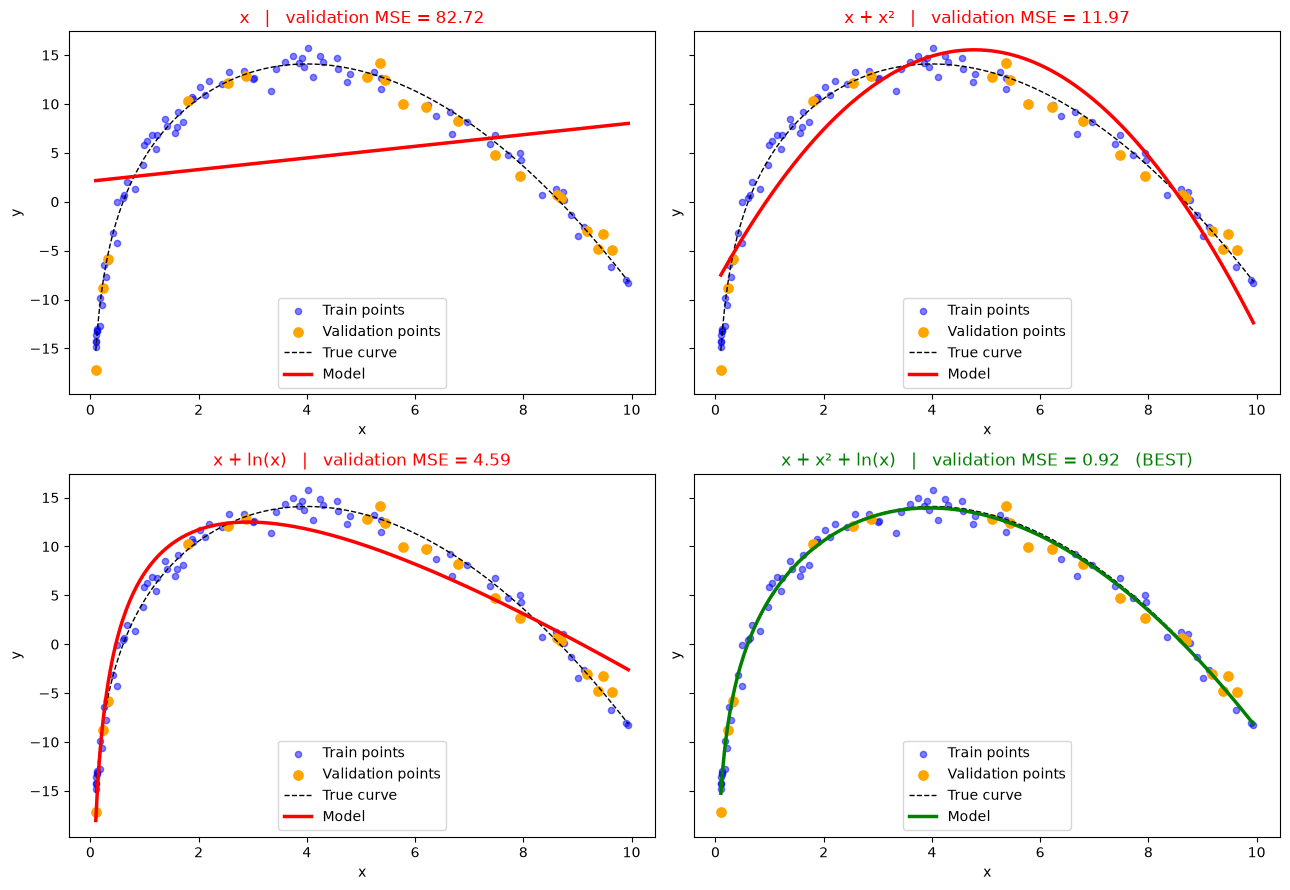

In [10]:
# Draw each model's curve to see why one model is best
x_line = np.linspace(X.min(), X.max(), 300)
y_true = 2*x_line - 0.5*x_line**2 + 8*np.log(x_line) + 3   # the real curve, no noise

val_mse = {name: np.mean((m.predict(X_val) - y_val) ** 2) for name, m in models.items()}
best = min(val_mse, key=val_mse.get)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)

for ax, (name, m) in zip(axes.flat, models.items()):
    color = "green" if name == best else "red"

    ax.scatter(X_train, y_train, color="blue", s=20, alpha=0.5, label="Train points")
    ax.scatter(X_val, y_val, color="orange", s=45, label="Validation points")
    ax.plot(x_line, y_true, "k--", linewidth=1, label="True curve")
    ax.plot(x_line, m.predict(x_line), color=color, linewidth=2.5, label="Model")

    title = f"{name}   |   validation MSE = {val_mse[name]:.2f}"
    ax.set_title(title + ("   (BEST)" if name == best else ""), color=color)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="lower center")

plt.tight_layout()
plt.show()

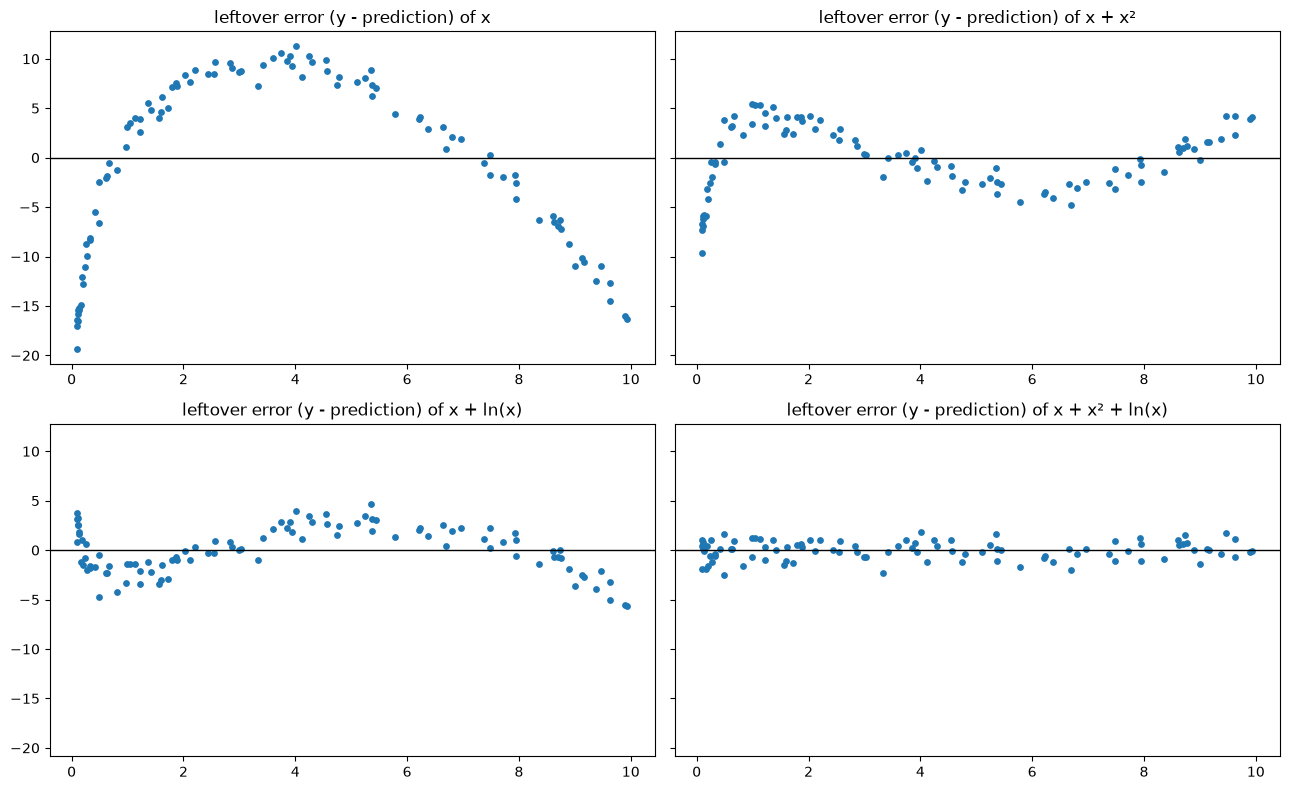

In [11]:
# Residuals: the part of y each model failed to explain
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, (name, m) in zip(axes.flat, models.items()):
    ax.scatter(X, y - m.predict(X), s=15)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"leftover error (y - prediction) of {name}")
plt.tight_layout()
plt.show()